# Phase 5c — Graded Relevance (nDCG and AV-distance threshold sweep)

Revision step 7 from `NEXT_STEPS.md` (PeerJ resubmission).

Reviewers called "same quadrant = relevant" too coarse: MERGE gives continuous arousal–valence (AV) labels, and
two tracks on either side of a quadrant boundary can be closer than two tracks in the same quadrant. This
notebook adds two graded or continuous relevance definitions. Quadrant precision stays as one metric among several.

* **nDCG@K with Gaussian AV relevance:** rel(q, c) = exp(−d²/(2σ²)), where d is the Euclidean AV distance.
  σ = 0.10 is the primary setting; σ ∈ {0.05, 0.20} is reported as a sensitivity check. The ideal DCG uses the
  best possible ranking of the whole catalog for that query, so nDCG = 1 means "retrieved the K AV-nearest tracks".
* **Threshold precision P@K(τ):** a candidate is relevant if d ≤ τ, swept over τ ∈ [0.05, 0.30]
  (the median pairwise AV distance in the catalog is 0.33). Each query also gets a **chance level**: the fraction
  of the catalog within τ of it, which is the expected P@K of a random ranking.

Setup is identical to Phase 5b: one shared 2,075-track catalog, shared queries (tracks in the same subset of both
the audio and the lyrics split), α tuned on the shared validation set by quadrant P@10, and exact cosine top-k.
Paired tests use the same pairs, paired bootstrap CIs and Wilcoxon (Pratt) with Holm correction.

This notebook reads AV values and quadrants for evaluation only. It never reads `moods`, `genres` or `themes`.

In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import wilcoxon, spearmanr

warnings.filterwarnings('ignore')

ROOT = os.environ.get('MUSIC_RESEARCH_ROOT', os.path.abspath('.'))
OUT_DIR = os.path.join(ROOT, 'outputs')

K_LIST  = [5, 10, 20]
ALPHAS  = [0.2, 0.4, 0.5, 0.6, 0.8]
SIGMAS  = [0.05, 0.10, 0.20]
SIGMA_MAIN = 0.10
TAUS    = [0.05, 0.075, 0.10, 0.15, 0.20, 0.25, 0.30]
N_BOOT  = 10_000
SEED    = 42
SCHEMES = {'tvt_70_15_15': '70/15/15', 'tvt_40_30_30': '40/30/30'}

audio_df  = pd.read_parquet(os.path.join(OUT_DIR, 'audio_features.parquet'))
lyrics_df = pd.read_parquet(os.path.join(OUT_DIR, 'lyrics_features.parquet'))
merged    = pd.read_parquet(os.path.join(OUT_DIR, 'merged_dataset.parquet'))

def l2n(X):
    X = np.asarray(X, dtype=np.float64)
    return X / np.linalg.norm(X, axis=1, keepdims=True)

audio_row = {s: i for i, s in enumerate(audio_df['song_id'])}
clap_all     = l2n(np.vstack(audio_df['audio_clap'].values))
clap_raw_all = np.vstack(audio_df['audio_clap_raw'].values)

cat_sids = lyrics_df['song_id'].tolist()
cat_pos  = {s: i for i, s in enumerate(cat_sids)}
a_idx    = [audio_row[s] for s in cat_sids]
X_audio  = clap_all[a_idx]
X_lyrics = l2n(np.vstack(lyrics_df['lyrics_sbert'].values))
X_early  = l2n(np.hstack([clap_raw_all[a_idx], np.vstack(lyrics_df['lyrics_sbert_raw'].values)]))

lab = merged.set_index('song_id').loc[cat_sids]
cat_quad = lab['quadrant'].values
cat_av   = lab[['arousal', 'valence']].values.astype(float)
D_AV     = np.linalg.norm(cat_av[:, None] - cat_av[None], axis=-1)     # (2075, 2075) AV distances

mm = merged[merged['is_multimodal']]
lyr_stem_to_sid = {os.path.splitext(os.path.basename(p))[0]: s for s, p in zip(mm['song_id'], mm['lyrics_path'])}

def read_split(modality, scheme, subset):
    folder = 'MERGE_Audio_Balanced' if modality == 'audio' else 'MERGE_Lyrics_Balanced'
    path = os.path.join(ROOT, folder, 'tvt_dataframes', scheme, f'{scheme}_{subset}_{modality}_balanced.csv')
    ids = pd.read_csv(path)['Song']
    if modality == 'lyrics':
        ids = ids.map(lyr_stem_to_sid).dropna()
    return set(ids)

cat_set = set(cat_sids)
shared = {}
for sc, lbl in SCHEMES.items():
    shared[lbl] = {sub: sorted(read_split('audio', sc, sub) & read_split('lyrics', sc, sub) & cat_set)
                   for sub in ['validate', 'test']}
    print(f"{lbl}: shared val={len(shared[lbl]['validate'])}  shared test={len(shared[lbl]['test'])}")

off = D_AV[np.triu_indices(len(cat_sids), 1)]
print('Pairwise AV distance percentiles (1, 5, 10, 25, 50%):', np.percentile(off, [1, 5, 10, 25, 50]).round(3))

70/15/15: shared val=305  shared test=302
40/30/30: shared val=616  shared test=617
Pairwise AV distance percentiles (1, 5, 10, 25, 50%): [0.014 0.044 0.072 0.161 0.328]


## 1. Retrieval and per-query graded metrics

DCG@K = Σᵢ relᵢ / log₂(i + 1). The ideal DCG sorts all catalog tracks (except the query) by AV distance.
For threshold precision, the per-query chance level is |{c ≠ q : d(q, c) ≤ τ}| / (N − 1).

In [2]:
S_audio, S_lyrics, S_early = X_audio @ X_audio.T, X_lyrics @ X_lyrics.T, X_early @ X_early.T
STRATEGIES = ['audio_only', 'lyrics_only'] + [f'late_{a}' for a in ALPHAS] + ['early_fusion']

def strategy_scores(name, rows):
    if name == 'audio_only':   return S_audio[rows]
    if name == 'lyrics_only':  return S_lyrics[rows]
    if name == 'early_fusion': return S_early[rows]
    a = float(name.split('_')[1])
    return a * S_audio[rows] + (1 - a) * S_lyrics[rows]

def topk(S, rows, kmax):
    S = S.copy(); S[np.arange(len(rows)), rows] = -np.inf
    part = np.argpartition(-S, kmax, axis=1)[:, :kmax]
    order = np.take_along_axis(S, part, axis=1).argsort(axis=1)[:, ::-1]
    return np.take_along_axis(part, order, axis=1)

KMAX = max(K_LIST)
DISC = 1.0 / np.log2(np.arange(2, KMAX + 2))

def ideal_dcg(rows):
    # AV-nearest KMAX tracks per query, excluding the query itself
    D = D_AV[rows].copy(); D[np.arange(len(rows)), rows] = np.inf
    d_ideal = np.sort(D, axis=1)[:, :KMAX]
    return {s: np.cumsum(np.exp(-d_ideal**2 / (2 * s**2)) * DISC, axis=1) for s in SIGMAS}

def chance_levels(rows):
    D = D_AV[rows].copy(); D[np.arange(len(rows)), rows] = np.inf
    n = len(cat_sids) - 1
    return {t: (D <= t).sum(axis=1) / n for t in TAUS}

def evaluate(query_sids, strategies=STRATEGIES):
    rows = np.array([cat_pos[s] for s in query_sids])
    idcg, chance = ideal_dcg(rows), chance_levels(rows)
    out = []
    for st in strategies:
        top = topk(strategy_scores(st, rows), rows, KMAX)
        d_top = np.take_along_axis(D_AV[rows], top, axis=1)
        q_top = cat_quad[top] == cat_quad[rows][:, None]
        for k in K_LIST:
            rec = {'strategy': st, 'song_id': query_sids, 'quadrant': cat_quad[rows], 'k': k,
                   'quad_precision': q_top[:, :k].mean(1), 'av_dist': d_top[:, :k].mean(1)}
            for s in SIGMAS:
                dcg = (np.exp(-d_top[:, :k]**2 / (2 * s**2)) * DISC[:k]).sum(1)
                rec[f'ndcg_s{s}'] = dcg / idcg[s][:, k - 1]
            for t in TAUS:
                rec[f'p_tau{t}'] = (d_top[:, :k] <= t).mean(1)
                rec[f'chance_tau{t}'] = chance[t]
            out.append(pd.DataFrame(rec))
    return pd.concat(out, ignore_index=True)

# α selection: same rule as Phase 5b (quadrant P@10 on shared validation), plus a check with nDCG@10
best_alpha = {}
for lbl in SCHEMES.values():
    rv = evaluate(shared[lbl]['validate'], [f'late_{a}' for a in ALPHAS])
    rv = rv[rv.k == 10].groupby('strategy')[['quad_precision', f'ndcg_s{SIGMA_MAIN}']].mean()
    best_alpha[lbl] = rv['quad_precision'].idxmax()
    print(f'{lbl} validation sweep (K=10):\n{rv.round(4).to_string()}')
    print(f"→ selected {best_alpha[lbl]} (by quad P@10); nDCG@10 would pick {rv[f'ndcg_s{SIGMA_MAIN}'].idxmax()}\n")

per_query = []
for lbl in SCHEMES.values():
    r = evaluate(shared[lbl]['test']); r['split'] = lbl; per_query.append(r)
per_query = pd.concat(per_query, ignore_index=True)

# Random-ranking reference for nDCG (Monte Carlo, 200 random top-K draws per query)
rng = np.random.default_rng(SEED)
rand_ndcg = {}
for lbl in SCHEMES.values():
    rows = np.array([cat_pos[s] for s in shared[lbl]['test']])
    idcg = ideal_dcg(rows)
    vals = {(s, k): [] for s in SIGMAS for k in K_LIST}
    for _ in range(200):
        pick = np.stack([rng.choice(np.delete(np.arange(len(cat_sids)), r), KMAX, replace=False) for r in rows])
        d = np.take_along_axis(D_AV[rows], pick, axis=1)
        for s in SIGMAS:
            for k in K_LIST:
                vals[(s, k)].append(((np.exp(-d[:, :k]**2 / (2 * s**2)) * DISC[:k]).sum(1) / idcg[s][:, k - 1]).mean())
    rand_ndcg[lbl] = {key: float(np.mean(v)) for key, v in vals.items()}
    print(f'{lbl} random-ranking nDCG@10 (σ=0.10): {rand_ndcg[lbl][(SIGMA_MAIN, 10)]:.3f}')

70/15/15 validation sweep (K=10):
          quad_precision  ndcg_s0.1
strategy                           
late_0.2          0.5852     0.4173
late_0.4          0.5885     0.4169
late_0.5          0.5820     0.4145
late_0.6          0.5813     0.4127
late_0.8          0.5748     0.4083
→ selected late_0.4 (by quad P@10); nDCG@10 would pick late_0.2



40/30/30 validation sweep (K=10):
          quad_precision  ndcg_s0.1
strategy                           
late_0.2          0.5735     0.4007
late_0.4          0.5758     0.4029
late_0.5          0.5752     0.4052
late_0.6          0.5763     0.4053
late_0.8          0.5718     0.3993
→ selected late_0.6 (by quad P@10); nDCG@10 would pick late_0.6



70/15/15 random-ranking nDCG@10 (σ=0.10): 0.186


40/30/30 random-ranking nDCG@10 (σ=0.10): 0.188


## 2. Per-strategy means with bootstrap 95% CIs

In [3]:
def boot_ci(x, n=N_BOOT):
    x = np.asarray(x, dtype=float)
    m = x[rng.integers(0, len(x), size=(n, len(x)))].mean(1)
    return np.percentile(m, [2.5, 97.5])

METRICS = ['quad_precision', 'av_dist'] + [f'ndcg_s{s}' for s in SIGMAS] + [f'p_tau{t}' for t in TAUS]
summ = []
for (lbl, st, k), g in per_query.groupby(['split', 'strategy', 'k']):
    row = {'split': lbl, 'strategy': st, 'k': k, 'n_queries': len(g), 'selected_alpha': st == best_alpha[lbl]}
    for m in METRICS:
        lo, hi = boot_ci(g[m].values)
        row[m], row[f'{m}_ci_lo'], row[f'{m}_ci_hi'] = g[m].mean(), lo, hi
    for t in TAUS:
        row[f'chance_tau{t}'] = g[f'chance_tau{t}'].mean()
    for s in SIGMAS:
        row[f'random_ndcg_s{s}'] = rand_ndcg[lbl][(s, k)]
    summ.append(row)
summary = pd.DataFrame(summ)
summary['strategy'] = pd.Categorical(summary['strategy'], STRATEGIES, ordered=True)
summary = summary.sort_values(['split', 'k', 'strategy']).reset_index(drop=True)
summary.to_csv(os.path.join(OUT_DIR, 'graded_relevance_summary.csv'), index=False)
per_query.to_parquet(os.path.join(OUT_DIR, 'graded_relevance_per_query.parquet'), index=False)

f = lambda r, m: f"{r[m]:.3f} [{r[m+'_ci_lo']:.3f}, {r[m+'_ci_hi']:.3f}]"
for lbl in SCHEMES.values():
    s = summary[(summary.split == lbl) & (summary.k == 10) &
                summary.strategy.isin(['audio_only', 'lyrics_only', best_alpha[lbl], 'early_fusion'])]
    print(f'\n=== {lbl} shared test, K=10 (n={s.n_queries.iloc[0]}) — mean [95% CI] ===')
    print(pd.DataFrame({c: s.apply(lambda r: f(r, m), axis=1).values for c, m in
                        [('Quad P', 'quad_precision'), ('nDCG σ=.05', 'ndcg_s0.05'),
                         ('nDCG σ=.10', 'ndcg_s0.1'), ('nDCG σ=.20', 'ndcg_s0.2')]},
                       index=s.strategy.astype(str)).to_string())
    print(f"random nDCG@10: σ=.05 {rand_ndcg[lbl][(0.05,10)]:.3f}, σ=.10 {rand_ndcg[lbl][(0.1,10)]:.3f}, "
          f"σ=.20 {rand_ndcg[lbl][(0.2,10)]:.3f}")
    tt = pd.DataFrame({f'τ={t}': s[f'p_tau{t}'].round(3).values for t in TAUS}, index=s.strategy.astype(str))
    tt.loc['chance'] = [s[f'chance_tau{t}'].iloc[0].round(3) for t in TAUS]
    print(f'\nThreshold P@10(τ):\n{tt.to_string()}')
print('\nSaved: graded_relevance_summary.csv, graded_relevance_per_query.parquet')


=== 70/15/15 shared test, K=10 (n=302) — mean [95% CI] ===
                            Quad P            nDCG σ=.05            nDCG σ=.10            nDCG σ=.20
strategy                                                                                            
audio_only    0.372 [0.345, 0.399]  0.128 [0.111, 0.145]  0.258 [0.236, 0.280]  0.461 [0.440, 0.483]
lyrics_only   0.601 [0.568, 0.635]  0.236 [0.213, 0.259]  0.427 [0.398, 0.456]  0.642 [0.616, 0.667]
late_0.4      0.616 [0.582, 0.649]  0.239 [0.216, 0.261]  0.431 [0.403, 0.458]  0.644 [0.619, 0.668]
early_fusion  0.604 [0.571, 0.638]  0.236 [0.213, 0.259]  0.428 [0.400, 0.456]  0.642 [0.617, 0.667]
random nDCG@10: σ=.05 0.082, σ=.10 0.186, σ=.20 0.390

Threshold P@10(τ):
              τ=0.05  τ=0.075  τ=0.1  τ=0.15  τ=0.2  τ=0.25  τ=0.3
strategy                                                          
audio_only     0.101    0.155  0.216   0.319  0.402   0.477  0.551
lyrics_only    0.174    0.276  0.384   0.518  0.608   0.679

## 3. Paired significance tests

Same pairs as Phase 5b. One Holm family per (split, K, metric). Metrics tested: nDCG at each σ and
threshold precision at each τ.

In [4]:
def holm(p):
    p = np.asarray(p); order = np.argsort(p); m = len(p)
    adj = np.empty(m); run = 0.0
    for rank, i in enumerate(order):
        run = max(run, (m - rank) * p[i]); adj[i] = min(1.0, run)
    return adj

tests = []
for lbl in SCHEMES.values():
    la = best_alpha[lbl]
    pairs = [(la, 'lyrics_only'), (la, 'audio_only'), (la, 'early_fusion'),
             ('early_fusion', 'lyrics_only'), ('lyrics_only', 'audio_only')]
    for k in K_LIST:
        sub = per_query[(per_query.split == lbl) & (per_query.k == k)]
        for metric in [f'ndcg_s{s}' for s in SIGMAS] + [f'p_tau{t}' for t in TAUS]:
            wide = sub.pivot(index='song_id', columns='strategy', values=metric)
            fam = []
            for a, b in pairs:
                d = (wide[a] - wide[b]).values
                lo, hi = boot_ci(d); nz = int((d != 0).sum())
                p = wilcoxon(wide[a], wide[b], zero_method='pratt').pvalue if nz else 1.0
                fam.append({'split': lbl, 'k': k, 'metric': metric, 'A': a, 'B': b,
                            'mean_A': wide[a].mean(), 'mean_B': wide[b].mean(), 'diff': d.mean(),
                            'ci_lo': lo, 'ci_hi': hi, 'n_queries': len(d),
                            'A_better': int((d > 0).sum()), 'B_better': int((d < 0).sum()), 'p_wilcoxon': p})
            for r, ph in zip(fam, holm([r['p_wilcoxon'] for r in fam])):
                r['p_holm'] = ph; r['significant_0.05'] = ph < 0.05
            tests += fam
tests = pd.DataFrame(tests)
tests.to_csv(os.path.join(OUT_DIR, 'graded_relevance_tests.csv'), index=False)

show = tests[(tests.k == 10) & tests.metric.isin(['ndcg_s0.05', 'ndcg_s0.1', 'ndcg_s0.2', 'p_tau0.1', 'p_tau0.2'])].copy()
show['diff [95% CI]'] = show.apply(lambda r: f"{r['diff']:+.3f} [{r.ci_lo:+.3f}, {r.ci_hi:+.3f}]", axis=1)
show['W/L'] = show.A_better.astype(str) + '/' + show.B_better.astype(str)
for lbl in SCHEMES.values():
    print(f'\n=== {lbl}, K=10 ===')
    print(show[show.split == lbl][['metric', 'A', 'B', 'diff [95% CI]', 'W/L', 'p_holm', 'significant_0.05']]
          .to_string(index=False, float_format=lambda x: f'{x:.2g}'))
print('\nSaved: graded_relevance_tests.csv')


=== 70/15/15, K=10 ===
    metric            A            B           diff [95% CI]     W/L  p_holm  significant_0.05
ndcg_s0.05     late_0.4  lyrics_only +0.003 [-0.003, +0.009] 157/145    0.52             False
ndcg_s0.05     late_0.4   audio_only +0.111 [+0.090, +0.132]  213/89 6.8e-19              True
ndcg_s0.05     late_0.4 early_fusion +0.003 [-0.003, +0.008] 159/142    0.52             False
ndcg_s0.05 early_fusion  lyrics_only +0.000 [-0.001, +0.002] 126/101    0.52             False
ndcg_s0.05  lyrics_only   audio_only +0.108 [+0.087, +0.130]  209/93 5.4e-17              True
 ndcg_s0.1     late_0.4  lyrics_only +0.004 [-0.003, +0.011] 151/151     0.9             False
 ndcg_s0.1     late_0.4   audio_only +0.173 [+0.144, +0.202]  224/78 2.6e-23              True
 ndcg_s0.1     late_0.4 early_fusion +0.003 [-0.004, +0.010] 153/148     0.9             False
 ndcg_s0.1 early_fusion  lyrics_only +0.001 [-0.001, +0.003] 121/111     0.9             False
 ndcg_s0.1  lyrics_only   

## 4. Do the conclusions change with graded relevance?

For each comparison, check whether the sign and Holm significance agree across quadrant precision (Phase 5b),
nDCG at each σ, and threshold precision at each τ. Also check how well quadrant precision tracks nDCG per query.

In [5]:
q_tests = pd.read_csv(os.path.join(OUT_DIR, 'significance_tests.csv'))
q_tests = q_tests[q_tests.metric == 'precision'].assign(metric='quad_precision')
allt = pd.concat([q_tests[tests.columns.intersection(q_tests.columns)], tests], ignore_index=True)

def verdict(r):
    if not r['significant_0.05']: return 'n.s.'
    return 'A>B' if r['diff'] > 0 else 'A<B'

allt['verdict'] = allt.apply(verdict, axis=1)
allt['pair'] = allt.A.str.replace('late_', 'late α=') + ' vs ' + allt.B
col_order = ['quad_precision'] + [f'ndcg_s{s}' for s in SIGMAS] + [f'p_tau{t}' for t in TAUS]
agreement = []
for lbl in SCHEMES.values():
    for k in [5, 10]:
        t = allt[(allt.split == lbl) & (allt.k == k)].pivot(index='pair', columns='metric', values='verdict')
        t = t[[c for c in col_order if c in t.columns]]
        print(f'\n=== {lbl}, K={k} (Holm-significant direction; n.s. = not significant) ===')
        print(t.to_string())
        agreement.append(t.assign(split=lbl, k=k).reset_index())
pd.concat(agreement).to_csv(os.path.join(OUT_DIR, 'graded_relevance_agreement.csv'), index=False)

print('\nPer-query Spearman ρ between quadrant P@10 and nDCG@10 (σ=0.10):')
for (lbl, st), g in per_query[per_query.k == 10].groupby(['split', 'strategy']):
    if st in ['audio_only', 'lyrics_only', best_alpha[lbl], 'early_fusion']:
        print(f'  {lbl:9s} {st:13s} ρ = {spearmanr(g.quad_precision, g["ndcg_s0.1"]).statistic:.2f}')

# Is quadrant precision unfair to queries near a quadrant boundary?
bd = np.minimum(np.abs(cat_av[:, 0] - 0.5), np.abs(cat_av[:, 1] - 0.5))
pq = per_query[(per_query.k == 10)].copy()
pq['boundary_dist'] = bd[[cat_pos[s] for s in pq.song_id]]
print('\nSpearman ρ with query distance to nearest quadrant boundary (K=10):')
for (lbl, st), g in pq.groupby(['split', 'strategy']):
    if st in ['audio_only', 'lyrics_only', best_alpha[lbl]]:
        print(f'  {lbl:9s} {st:13s} quad P: ρ={spearmanr(g.boundary_dist, g.quad_precision).statistic:+.2f}   '
              f'nDCG σ=.10: ρ={spearmanr(g.boundary_dist, g["ndcg_s0.1"]).statistic:+.2f}')
print('Saved: graded_relevance_agreement.csv')


=== 70/15/15, K=5 (Holm-significant direction; n.s. = not significant) ===
metric                      quad_precision ndcg_s0.05 ndcg_s0.1 ndcg_s0.2 p_tau0.05 p_tau0.075 p_tau0.1 p_tau0.15 p_tau0.2 p_tau0.25 p_tau0.3
pair                                                                                                                                         
early_fusion vs lyrics_only           n.s.       n.s.      n.s.      n.s.      n.s.       n.s.     n.s.      n.s.     n.s.      n.s.     n.s.
late α=0.4 vs audio_only               A>B        A>B       A>B       A>B       A>B        A>B      A>B       A>B      A>B       A>B      A>B
late α=0.4 vs early_fusion            n.s.       n.s.      n.s.      n.s.      n.s.       n.s.     n.s.      n.s.     n.s.      n.s.     n.s.
late α=0.4 vs lyrics_only             n.s.       n.s.      n.s.      n.s.      n.s.       n.s.     n.s.      n.s.     n.s.      n.s.     n.s.
lyrics_only vs audio_only              A>B        A>B       A>B       A>

## 5. Figure: graded relevance on the shared test split
Left: nDCG@K (σ = 0.10) with 95% CIs. Right: P@10 as a function of the AV-distance threshold τ, with the chance level.
Colors pass the colorblind-safety check; each strategy also has its own marker.

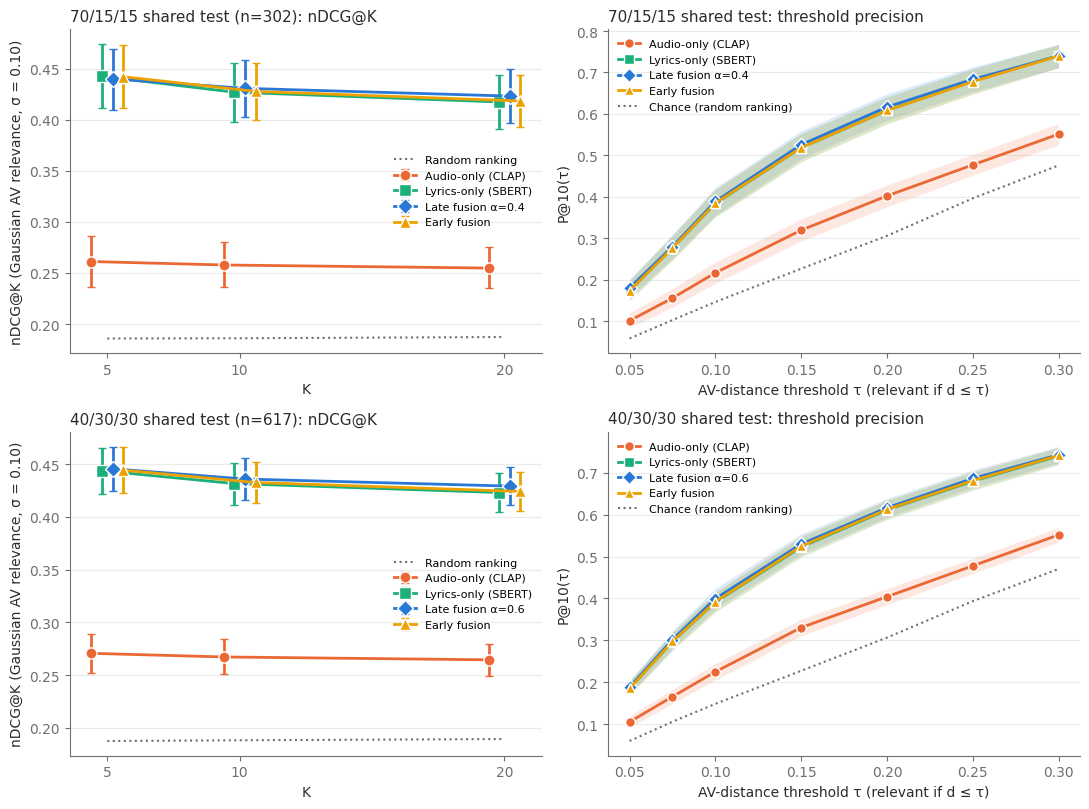

Saved: graded_relevance.png


In [6]:
COL = {'audio_only': ('#eb6834', 'o', 'Audio-only (CLAP)'), 'lyrics_only': ('#1baf7a', 's', 'Lyrics-only (SBERT)'),
       'late': ('#2a78d6', 'D', 'Late fusion'), 'early_fusion': ('#eda100', '^', 'Early fusion')}
INK, MUTED = '#2b2b2b', '#6f6f6f'
plt.rcParams.update({'axes.edgecolor': MUTED, 'axes.labelcolor': INK, 'xtick.color': MUTED, 'ytick.color': MUTED,
                     'axes.spines.top': False, 'axes.spines.right': False, 'font.size': 10})

fig, axes = plt.subplots(2, 2, figsize=(11, 8.2))
for row, lbl in enumerate(SCHEMES.values()):
    strats = ['audio_only', 'lyrics_only', best_alpha[lbl], 'early_fusion']
    n = summary[summary.split == lbl].n_queries.iloc[0]
    ax = axes[row, 0]
    for j, st in enumerate(strats):
        c, mk, name = COL.get(st, COL['late'])
        if st.startswith('late_'): name = f"Late fusion α={st.split('_')[1]}"
        s = summary[(summary.split == lbl) & (summary.strategy == st)].sort_values('k')
        x = np.array(K_LIST) + (j - 1.5) * 0.4
        ax.errorbar(x, s['ndcg_s0.1'], yerr=[s['ndcg_s0.1'] - s['ndcg_s0.1_ci_lo'], s['ndcg_s0.1_ci_hi'] - s['ndcg_s0.1']],
                    fmt=mk + '-', color=c, label=name, capsize=3, lw=2, ms=8, mec='white', mew=1)
    ax.plot(K_LIST, [rand_ndcg[lbl][(0.1, k)] for k in K_LIST], ls=':', color=MUTED, lw=1.5, label='Random ranking')
    ax.set_xticks(K_LIST); ax.set_xlabel('K'); ax.set_ylabel('nDCG@K (Gaussian AV relevance, σ = 0.10)')
    ax.set_title(f'{lbl} shared test (n={n}): nDCG@K', fontsize=11, color=INK, loc='left')
    ax.grid(axis='y', alpha=0.25); ax.legend(fontsize=8, frameon=False)

    ax = axes[row, 1]
    for st in strats:
        c, mk, name = COL.get(st, COL['late'])
        if st.startswith('late_'): name = f"Late fusion α={st.split('_')[1]}"
        s = summary[(summary.split == lbl) & (summary.strategy == st) & (summary.k == 10)].iloc[0]
        y  = [s[f'p_tau{t}'] for t in TAUS]
        lo = [s[f'p_tau{t}_ci_lo'] for t in TAUS]; hi = [s[f'p_tau{t}_ci_hi'] for t in TAUS]
        ax.fill_between(TAUS, lo, hi, color=c, alpha=0.15, lw=0)
        ax.plot(TAUS, y, marker=mk, color=c, lw=2, ms=7, mec='white', mew=1, label=name)
    s0 = summary[(summary.split == lbl) & (summary.k == 10)].iloc[0]
    ax.plot(TAUS, [s0[f'chance_tau{t}'] for t in TAUS], ls=':', color=MUTED, lw=1.5, label='Chance (random ranking)')
    ax.set_xlabel('AV-distance threshold τ (relevant if d ≤ τ)'); ax.set_ylabel('P@10(τ)')
    ax.set_title(f'{lbl} shared test: threshold precision', fontsize=11, color=INK, loc='left')
    ax.grid(axis='y', alpha=0.25); ax.legend(fontsize=8, frameon=False, loc='upper left')
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, 'graded_relevance.png'), dpi=200, bbox_inches='tight')
plt.show()
print('Saved: graded_relevance.png')